Imports and variables

In [1]:
import torch
import torch.nn as nn
import math
import random

SEED = 42
torch.manual_seed(SEED)
random.seed(SEED)

BOS = 0
EOS = 51
VOCAB_SIZE = 52
SEQ_LEN = 10
BATCH_SIZE = 4

D_MODEL = 256
NUM_HEADS = 8
HEAD_DIM = D_MODEL // NUM_HEADS

BOTTLENECK_DIM = 8

Generating a batch: multiple sequences are combined into a single tensor

In [2]:
def generate_batch(batch_size):
    examples = []

    for i in range(batch_size):
        x = torch.randperm(50)[:SEQ_LEN] + 1
        examples.append(x)

    inputs = torch.stack(examples)

    targets = torch.flip(inputs, dims=[1])

    bos_column = torch.full((batch_size, 1), BOS)
    eos_column = torch.full((batch_size, 1), EOS)

    decoder_inputs = torch.cat([bos_column, targets], dim=1)
    decoder_targets = torch.cat([targets, eos_column], dim=1)

    return inputs, decoder_inputs, decoder_targets

In [3]:
inputs, decoder_inputs, decoder_targets = generate_batch(BATCH_SIZE)

print("Encoder input:", inputs[0].tolist())
print("Decoder input:", decoder_inputs[0].tolist())
print("Decoder target:", decoder_targets[0].tolist())

Encoder input: [43, 18, 31, 35, 21, 26, 1, 9, 37, 19]
Decoder input: [0, 19, 37, 9, 1, 26, 21, 35, 31, 18, 43]
Decoder target: [19, 37, 9, 1, 26, 21, 35, 31, 18, 43, 51]


## TRANSFORMER

Сreate positional encoding: a matrix filled with sine and cosine values to preserve information about token positions.

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len):
        super().__init__()

        pe = torch.zeros(1, max_len, d_model)

        for pos in range(max_len):
            for i in range(d_model // 2):
                angle = pos / (10000 ** (2 * i / d_model))

                pe[0, pos, 2 * i] = math.sin(angle)
                pe[0, pos, 2 * i + 1] = math.cos(angle)

        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:, :x.shape[1], :]

DEMO

In [5]:
positional_encoding = PositionalEncoding(
    D_MODEL,
    SEQ_LEN + 1
)

encoder_test = torch.zeros(BATCH_SIZE, SEQ_LEN, D_MODEL)
decoder_test = torch.zeros(BATCH_SIZE, SEQ_LEN + 1, D_MODEL)

encoder_result = positional_encoding(encoder_test)
decoder_result = positional_encoding(decoder_test)

print("Encoder:", encoder_result[:1, :5, :5])
print("Decoder:", decoder_result[:1, :5, :5])

Encoder: tensor([[[ 0.0000,  1.0000,  0.0000,  1.0000,  0.0000],
         [ 0.8415,  0.5403,  0.8020,  0.5974,  0.7617],
         [ 0.9093, -0.4161,  0.9581, -0.2863,  0.9870],
         [ 0.1411, -0.9900,  0.3428, -0.9394,  0.5173],
         [-0.7568, -0.6536, -0.5486, -0.8361, -0.3167]]])
Decoder: tensor([[[ 0.0000,  1.0000,  0.0000,  1.0000,  0.0000],
         [ 0.8415,  0.5403,  0.8020,  0.5974,  0.7617],
         [ 0.9093, -0.4161,  0.9581, -0.2863,  0.9870],
         [ 0.1411, -0.9900,  0.3428, -0.9394,  0.5173],
         [-0.7568, -0.6536, -0.5486, -0.8361, -0.3167]]])


In [6]:
class FeedForward(nn.Module):
    def __init__(self, d_model):
        super().__init__()

        self.ffn1 = nn.Linear(d_model, 4 * d_model)
        self.relu = nn.ReLU()
        self.ffn2 = nn.Linear(4 * d_model, d_model)

    def forward(self, x):
        x = self.ffn1(x)
        x = self.relu(x)
        x = self.ffn2(x)

        return x

DEMO

In [7]:
ffn = FeedForward(D_MODEL)

test_input = torch.randn(BATCH_SIZE, SEQ_LEN, D_MODEL)

test_output = ffn(test_input)

print(test_output[:1, :5, :5])

tensor([[[ 0.0941, -0.1643,  0.0547,  0.0375, -0.0315],
         [-0.0074, -0.1770,  0.0548, -0.1514,  0.1480],
         [-0.0733,  0.1058,  0.2550, -0.2178,  0.1140],
         [ 0.3491,  0.1711,  0.5552, -0.2552,  0.0639],
         [-0.0855,  0.1771,  0.2042,  0.2540, -0.1758]]],
       grad_fn=<SliceBackward0>)


Implemented Multi-Head Attention

In [8]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, kv_dim=None):
        super().__init__()

        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        if kv_dim is None:
            kv_dim = d_model

        self.W_Q = nn.Linear(d_model, d_model, bias=False)
        self.W_K = nn.Linear(kv_dim, d_model, bias=False)
        self.W_V = nn.Linear(kv_dim, d_model, bias=False)
        self.W_O = nn.Linear(d_model, d_model, bias=False)

    def forward(self, query, key_value, causal=False):
        B, L_q, _ = query.shape
        L_k = key_value.shape[1]

        Q = self.W_Q(query)
        K = self.W_K(key_value)
        V = self.W_V(key_value)

        Q = Q.reshape(B, L_q, self.num_heads, self.head_dim).transpose(1, 2)
        K = K.reshape(B, L_k, self.num_heads, self.head_dim).transpose(1, 2)
        V = V.reshape(B, L_k, self.num_heads, self.head_dim).transpose(1, 2)

        scores = Q @ K.transpose(-2, -1)
        scores = scores / math.sqrt(self.head_dim)

        if causal:
            if L_q != L_k:
                raise ValueError

            mask = torch.triu(
                torch.ones(L_q, L_k, dtype=torch.bool, device=query.device),
                diagonal=1
            )
            scores = scores.masked_fill(mask, float("-inf"))

        weights = torch.softmax(scores, dim=-1)
        output = weights @ V

        output = output.transpose(1, 2).reshape(B, L_q, -1)

        output = self.W_O(output)

        return output

DEMO

In [9]:
encoder_x = torch.randn(BATCH_SIZE, 10, D_MODEL)
decoder_x = torch.randn(BATCH_SIZE, 11, D_MODEL)
compressed_x = torch.randn(BATCH_SIZE, 10, BOTTLENECK_DIM)

# Encoder Self-Attention
encoder_attention = MultiHeadAttention(D_MODEL, NUM_HEADS)

encoder_result = encoder_attention(encoder_x, encoder_x)

# Decoder Masked Self-Attention
decoder_attention = MultiHeadAttention(D_MODEL, NUM_HEADS)

decoder_result = decoder_attention(
    decoder_x,
    decoder_x,
    causal=True
)

# Cross-Attention
cross_attention = MultiHeadAttention(
    D_MODEL,
    NUM_HEADS,
    kv_dim=BOTTLENECK_DIM
)

cross_result = cross_attention(
    decoder_x,
    compressed_x
)

print("Encoder:", encoder_result.shape)
print("Decoder:", decoder_result.shape)
print("Cross:", cross_result.shape)

Encoder: torch.Size([4, 10, 256])
Decoder: torch.Size([4, 11, 256])
Cross: torch.Size([4, 11, 256])


Implemented Encoder

In [10]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, max_len):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_len)

        self.attention = MultiHeadAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)

        self.ffn = FeedForward(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, tokens):
        x = self.embedding(tokens)
        x = self.positional_encoding(x)

        attention_output = self.attention(x, x)
        x = self.norm1(x + attention_output)

        ffn_output = self.ffn(x)
        x = self.norm2(x + ffn_output)

        return x

DEMO

In [11]:
encoder = Encoder(
    vocab_size=VOCAB_SIZE,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    max_len=SEQ_LEN
)

encoder_output = encoder(inputs)

print("Input:", inputs.shape)
print("Encoder output:", encoder_output.shape)

Input: torch.Size([4, 10])
Encoder output: torch.Size([4, 10, 256])


Implemented Decoder

In [12]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, max_len, bottleneck_dim):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_len)

        self.self_attention = MultiHeadAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)

        self.cross_attention = MultiHeadAttention(
            d_model, num_heads, kv_dim=bottleneck_dim
        )
        self.norm2 = nn.LayerNorm(d_model)

        self.ffn = FeedForward(d_model)
        self.norm3 = nn.LayerNorm(d_model)

    def forward(self, decoder_tokens, encoder_compressed):
        x = self.embedding(decoder_tokens)
        x = self.positional_encoding(x)

        self_attention_output = self.self_attention(x, x, causal=True)
        x = self.norm1(x + self_attention_output)

        cross_attention_output = self.cross_attention(
            x, encoder_compressed
        )
        x = self.norm2(x + cross_attention_output)

        ffn_output = self.ffn(x)
        x = self.norm3(x + ffn_output)

        return x

DEMO

In [13]:
decoder = Decoder(
    vocab_size=VOCAB_SIZE,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    max_len=SEQ_LEN + 1,
    bottleneck_dim=BOTTLENECK_DIM
)

encoder_compressed_test = torch.randn(
    BATCH_SIZE, SEQ_LEN, BOTTLENECK_DIM
)

decoder_output = decoder(
    decoder_inputs,
    encoder_compressed_test
)

print("Decoder input:", decoder_inputs.shape)
print("Bottleneck:", encoder_compressed_test.shape)
print("Decoder output:", decoder_output.shape)

Decoder input: torch.Size([4, 11])
Bottleneck: torch.Size([4, 10, 8])
Decoder output: torch.Size([4, 11, 256])


In [14]:
class Transformer(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, seq_len, bottleneck_dim):
        super().__init__()

        # Encoder
        self.encoder = Encoder(
            vocab_size,
            d_model,
            num_heads,
            max_len=seq_len
        )

        # Bottleneck
        self.bottleneck = nn.Linear(d_model, bottleneck_dim)
        self.bottleneck.requires_grad_(False)

        # Decoder
        self.decoder = Decoder(
            vocab_size,
            d_model,
            num_heads,
            max_len=seq_len + 1,
            bottleneck_dim=bottleneck_dim
        )

        # Output Linear
        self.output_projection = nn.Linear(d_model, vocab_size)

    def forward(self, encoder_tokens, decoder_tokens):

        # Encoder
        encoder_output = self.encoder(encoder_tokens)

        # Bottleneck
        compressed = self.bottleneck(encoder_output)

        # Decoder
        decoder_output = self.decoder(decoder_tokens, compressed)

        # Logits
        logits = self.output_projection(decoder_output)

        return logits

DEMO

In [15]:
model = Transformer(
    vocab_size=VOCAB_SIZE,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    seq_len=SEQ_LEN,
    bottleneck_dim=BOTTLENECK_DIM
)

print("Number of parameters:",
      sum(p.numel() for p in model.parameters()))

Number of parameters: 1755196


Predictions

In [16]:
logits = model(inputs, decoder_inputs)

predictions = logits.argmax(dim=-1)

print("Correct ans:", decoder_targets[0].tolist())
print("Ans:    ", predictions[0].tolist())

Correct ans: [19, 37, 9, 1, 26, 21, 35, 31, 18, 43, 51]
Ans:     [45, 23, 45, 35, 32, 43, 2, 2, 16, 27, 27]


## TRAINING

In [17]:
VAL_SIZE = 512

with torch.random.fork_rng():
    torch.manual_seed(2026)

    val_inputs, val_decoder_inputs, val_targets = generate_batch(VAL_SIZE)

In [18]:
@torch.no_grad()
def evaluate(model):
    was_training = model.training
    model.eval()

    device = next(model.parameters()).device

    total_loss = 0
    total_correct = 0
    total_exact = 0
    total_tokens = 0

    VAL_BATCH_SIZE = 64

    for start in range(0, VAL_SIZE, VAL_BATCH_SIZE):

        x = val_inputs[start:start + VAL_BATCH_SIZE].to(device)
        dec_x = val_decoder_inputs[start:start + VAL_BATCH_SIZE].to(device)
        targets = val_targets[start:start + VAL_BATCH_SIZE].to(device)

        logits = model(x, dec_x)

        loss = nn.functional.cross_entropy(
            logits.reshape(-1, VOCAB_SIZE),
            targets.reshape(-1),
            reduction="sum"
        )

        total_loss += loss.item()

        predictions = logits.argmax(dim=-1)

        correct = predictions == targets

        total_correct += correct.sum().item()
        total_tokens += targets.numel()

        total_exact += correct.all(dim=1).sum().item()

    model.train(was_training)

    return {
        "val_loss": total_loss / total_tokens,
        "token_accuracy": total_correct / total_tokens,
        "exact_match": total_exact / VAL_SIZE
    }

In [19]:
def train_model(
    bottleneck_dim,
    seed=42,
    num_steps=500,
    batch_size=32,
    eval_every=50,
    lr=0.001
):

    torch.manual_seed(seed)
    random.seed(seed)

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model = Transformer(
        vocab_size=VOCAB_SIZE,
        d_model=D_MODEL,
        num_heads=NUM_HEADS,
        seq_len=SEQ_LEN,
        bottleneck_dim=bottleneck_dim
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    history = {
        "step": [],
        "train_loss": [],
        "val_loss": [],
        "token_accuracy": [],
        "exact_match": []
    }

    torch.manual_seed(seed + 10000)

    metrics = evaluate(model)

    history["step"].append(0)
    history["train_loss"].append(float("nan"))
    history["val_loss"].append(metrics["val_loss"])
    history["token_accuracy"].append(metrics["token_accuracy"])
    history["exact_match"].append(metrics["exact_match"])

    running_loss = 0.0
    window_steps = 0

    model.train()

    for step in range(1, num_steps + 1):

        inputs, decoder_inputs, decoder_targets = generate_batch(batch_size)

        inputs = inputs.to(device)
        decoder_inputs = decoder_inputs.to(device)
        decoder_targets = decoder_targets.to(device)

        optimizer.zero_grad()

        logits = model(inputs, decoder_inputs)

        loss = criterion(
            logits.reshape(-1, VOCAB_SIZE),
            decoder_targets.reshape(-1)
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        window_steps += 1

        if step % eval_every == 0 or step == num_steps:

            metrics = evaluate(model)

            avg_train_loss = running_loss / window_steps

            history["step"].append(step)
            history["train_loss"].append(avg_train_loss)
            history["val_loss"].append(metrics["val_loss"])
            history["token_accuracy"].append(metrics["token_accuracy"])
            history["exact_match"].append(metrics["exact_match"])

            print(
                f"n={bottleneck_dim:3d} | "
                f"Step {step:4d} | "
                f"Train Loss: {avg_train_loss:.4f} | "
                f"Val Loss: {metrics['val_loss']:.4f} | "
                f"Exact Match: {metrics['exact_match']:.2%}"
            )

            running_loss = 0.0
            window_steps = 0

    return model, history

In [20]:
import pandas as pd
import gc

BOTTLENECK_DIMS = [2, 4, 8, 16, 32, 64, 128, 256]

all_histories = {}
summary = []

NUM_STEPS = 500
VAL_LOSS_THRESHOLD = 1.0

for n in BOTTLENECK_DIMS:

    print(f"\n{'=' * 45}")
    print(f"Training: bottleneck n = {n}")
    print(f"{'=' * 45}")

    trained_model, history = train_model(
        bottleneck_dim=n,
        seed=42,
        num_steps=NUM_STEPS,
        batch_size=32,
        eval_every=25,
        lr=0.0003
    )

    all_histories[n] = history

    steps_to_threshold = None

    for step, loss in zip(
        history["step"],
        history["val_loss"]
    ):
        if loss <= VAL_LOSS_THRESHOLD:
            steps_to_threshold = step
            break

    summary.append({
        "n": n,
        "final_val_loss": history["val_loss"][-1],
        "token_accuracy": history["token_accuracy"][-1],
        "exact_match": history["exact_match"][-1],
        "steps_to_threshold": steps_to_threshold
    })

    del trained_model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(summary)

print("\nRESULTS")
display(results_df)


Training: bottleneck n = 2
n=  2 | Step   25 | Train Loss: 3.8522 | Val Loss: 3.7160 | Exact Match: 0.00%
n=  2 | Step   50 | Train Loss: 3.6117 | Val Loss: 3.5325 | Exact Match: 0.00%
n=  2 | Step   75 | Train Loss: 3.4897 | Val Loss: 3.4683 | Exact Match: 0.00%
n=  2 | Step  100 | Train Loss: 3.4381 | Val Loss: 3.4240 | Exact Match: 0.00%
n=  2 | Step  125 | Train Loss: 3.4056 | Val Loss: 3.3882 | Exact Match: 0.00%
n=  2 | Step  150 | Train Loss: 3.3728 | Val Loss: 3.3727 | Exact Match: 0.00%
n=  2 | Step  175 | Train Loss: 3.3428 | Val Loss: 3.3215 | Exact Match: 0.00%
n=  2 | Step  200 | Train Loss: 3.2974 | Val Loss: 3.2761 | Exact Match: 0.00%
n=  2 | Step  225 | Train Loss: 3.2610 | Val Loss: 3.2381 | Exact Match: 0.00%
n=  2 | Step  250 | Train Loss: 3.2151 | Val Loss: 3.2134 | Exact Match: 0.00%
n=  2 | Step  275 | Train Loss: 3.1678 | Val Loss: 3.1531 | Exact Match: 0.00%
n=  2 | Step  300 | Train Loss: 3.1227 | Val Loss: 3.1022 | Exact Match: 0.00%
n=  2 | Step  325 | Trai

,n,final_val_loss,token_accuracy,exact_match,steps_to_threshold
0,2,2.864066,0.297940,0.000000,NaN
1,4,0.350105,0.921342,0.404297,350.0
2,8,0.007571,1.000000,1.000000,175.0
3,16,0.005730,1.000000,1.000000,150.0
4,32,0.005276,1.000000,1.000000,150.0
5,64,0.004134,1.000000,1.000000,150.0
6,128,0.003753,1.000000,1.000000,125.0
7,256,0.003219,1.000000,1.000000,100.0


## STATS

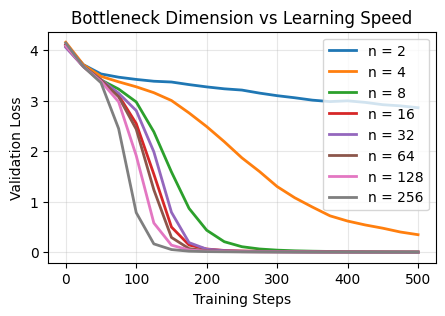

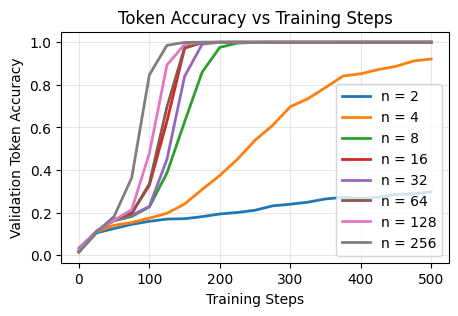

In [21]:
import matplotlib.pyplot as plt

# Validation Loss

plt.figure(figsize=(5, 3))

for n, history in all_histories.items():
    plt.plot(
        history["step"],
        history["val_loss"],
        label=f"n = {n}",
        linewidth=2
    )

plt.xlabel("Training Steps")
plt.ylabel("Validation Loss")
plt.title("Bottleneck Dimension vs Learning Speed")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Token Accuracy

plt.figure(figsize=(5, 3))

for n, history in all_histories.items():
    plt.plot(
        history["step"],
        history["token_accuracy"],
        label=f"n = {n}",
        linewidth=2
    )

plt.xlabel("Training Steps")
plt.ylabel("Validation Token Accuracy")
plt.title("Token Accuracy vs Training Steps")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

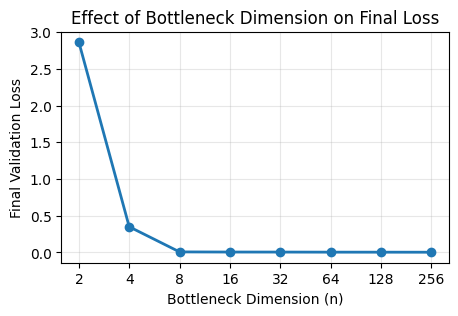

Pearson correlation:  -0.3189
Spearman correlation: -1.0000


In [22]:
plt.figure(figsize=(5, 3))

plt.plot(
    results_df["n"],
    results_df["final_val_loss"],
    marker="o",
    linewidth=2
)

plt.xscale("log", base=2)
plt.xticks(BOTTLENECK_DIMS, BOTTLENECK_DIMS)

plt.xlabel("Bottleneck Dimension (n)")
plt.ylabel("Final Validation Loss")
plt.title("Effect of Bottleneck Dimension on Final Loss")
plt.grid(True, alpha=0.3)

plt.show()

pearson = results_df["n"].corr(
    results_df["final_val_loss"],
    method="pearson"
)

spearman = results_df["n"].corr(
    results_df["final_val_loss"],
    method="spearman"
)

print(f"Pearson correlation:  {pearson:.4f}")
print(f"Spearman correlation: {spearman:.4f}")

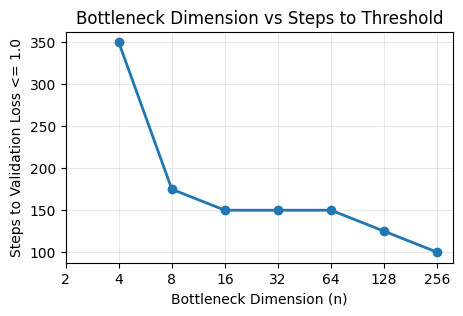

In [23]:
plt.figure(figsize=(5, 3))

plt.plot(
    results_df["n"],
    results_df["steps_to_threshold"],
    marker="o",
    linewidth=2
)

plt.xscale("log", base=2)
plt.xticks(BOTTLENECK_DIMS, BOTTLENECK_DIMS)

plt.xlabel("Bottleneck Dimension (n)")
plt.ylabel("Steps to Validation Loss <= 1.0")
plt.title("Bottleneck Dimension vs Steps to Threshold")
plt.grid(True, alpha=0.3)

plt.show()